# Mammographic Mass Classification: Interpretable Machine Learning and Sensitivity Analysis

This notebook presents a reproducible machine-learning experiment for binary classification of mammographic masses using structured clinical/radiological features.

## Research question

> How do an interpretable linear model and a nonlinear tree-based model perform for mammographic mass classification, and how sensitive are predictions to decision threshold and BI-RADS availability?

## Experimental design

- Data quality and target validation
- Stratified 60/20/20 train/validation/test split
- Leakage-safe preprocessing inside scikit-learn pipelines
- Logistic Regression as an interpretable baseline
- Random Forest as a nonlinear alternative
- Stratified 5-fold cross-validation
- Validation-based threshold analysis with an **illustrative** asymmetric error-cost ratio
- Final evaluation on an untouched test set
- Model interpretation
- BI-RADS feature-availability sensitivity analysis

**Scope:** This is a research experiment, not a clinical diagnostic system. The results should not be interpreted as evidence for autonomous diagnosis or clinical deployment.

## 1. Reproducibility and imports

The experiment uses a fixed random seed. All preprocessing that learns from the data is kept inside model pipelines to reduce the risk of data leakage during cross-validation.

In [1]:
import os
import glob
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

FIGURE_DIR = Path("/kaggle/working/results/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Experiment environment ready.")
print("RANDOM_STATE =", RANDOM_STATE)
print("Figure directory =", FIGURE_DIR)

Experiment environment ready.
RANDOM_STATE = 42
Figure directory = /kaggle/working/results/figures


## 2. Dataset loading and audit

The original experiment uses the mammographic masses dataset mounted in Kaggle. The loader below first checks the original path and then searches the Kaggle input directory for `mammographic_masses.data`, making the notebook less dependent on one exact mount path.

In [2]:
PREFERRED_DATA_PATH = "/kaggle/input/datasets/kubra57/mammographic/mammographic_masses.data"

if os.path.isfile(PREFERRED_DATA_PATH):
    DATA_PATH = PREFERRED_DATA_PATH
else:
    candidates = glob.glob(
        "/kaggle/input/**/mammographic_masses.data",
        recursive=True,
    )
    if not candidates:
        raise FileNotFoundError(
            "mammographic_masses.data was not found under /kaggle/input. "
            "Attach the dataset to the Kaggle notebook or update PREFERRED_DATA_PATH."
        )
    DATA_PATH = candidates[0]

columns = [
    "BI_RADS",
    "Age",
    "Shape",
    "Margin",
    "Density",
    "Severity",
]

df_raw = pd.read_csv(
    DATA_PATH,
    header=None,
    names=columns,
    na_values="?",
)

print("Dataset path:", DATA_PATH)
print("Shape:", df_raw.shape)
display(df_raw.head(10))

Dataset path: /kaggle/input/datasets/kubra57/mammographic/mammographic_masses.data
Shape: (961, 6)


,BI_RADS,Age,Shape,Margin,Density,Severity
0,5.0,67.0,3.0,5.0,3.0,1
1,4.0,43.0,1.0,1.0,NaN,1
2,5.0,58.0,4.0,5.0,3.0,1
3,4.0,28.0,1.0,1.0,3.0,0
4,5.0,74.0,1.0,5.0,NaN,1
5,4.0,65.0,1.0,NaN,3.0,0
6,4.0,70.0,NaN,NaN,3.0,0
7,5.0,42.0,1.0,NaN,3.0,0
8,5.0,57.0,1.0,5.0,3.0,1
9,5.0,60.0,NaN,5.0,1.0,1


In [3]:
audit = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing_count": df_raw.isna().sum(),
    "missing_percentage": (df_raw.isna().mean() * 100).round(2),
    "unique_values": df_raw.nunique(dropna=True),
})

print("Rows:", len(df_raw))
print("Columns:", len(df_raw.columns))
print("Exact duplicate rows:", df_raw.duplicated().sum())
display(audit)

print("Target distribution:")
display(
    pd.DataFrame({
        "count": df_raw["Severity"].value_counts(dropna=False),
        "percentage": (
            df_raw["Severity"]
            .value_counts(normalize=True, dropna=False)
            .mul(100)
            .round(2)
        ),
    })
)

Rows: 961
Columns: 6
Exact duplicate rows: 272


,dtype,missing_count,missing_percentage,unique_values
BI_RADS,float64,2,0.21,7
Age,float64,5,0.52,73
Shape,float64,31,3.23,4
Margin,float64,48,4.99,5
Density,float64,76,7.91,4
Severity,int64,0,0.00,2


Target distribution:


,count,percentage
Severity,,
0,516,53.69
1,445,46.31


In [4]:
for column in df_raw.columns:
    print(f"\n{column} unique values:")
    print(sorted(df_raw[column].dropna().unique()))

print("\nDescriptive statistics:")
display(df_raw.describe().T)

print("\nAge range:", df_raw["Age"].min(), "to", df_raw["Age"].max())
print("BI-RADS range:", df_raw["BI_RADS"].min(), "to", df_raw["BI_RADS"].max())
print("Severity values:", sorted(df_raw["Severity"].dropna().unique()))


BI_RADS unique values:
[np.float64(0.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(55.0)]

Age unique values:
[np.float64(18.0), np.float64(19.0), np.float64(20.0), np.float64(21.0), np.float64(22.0), np.float64(23.0), np.float64(24.0), np.float64(25.0), np.float64(26.0), np.float64(27.0), np.float64(28.0), np.float64(29.0), np.float64(30.0), np.float64(31.0), np.float64(32.0), np.float64(33.0), np.float64(34.0), np.float64(35.0), np.float64(36.0), np.float64(37.0), np.float64(38.0), np.float64(39.0), np.float64(40.0), np.float64(41.0), np.float64(42.0), np.float64(43.0), np.float64(44.0), np.float64(45.0), np.float64(46.0), np.float64(47.0), np.float64(48.0), np.float64(49.0), np.float64(50.0), np.float64(51.0), np.float64(52.0), np.float64(53.0), np.float64(54.0), np.float64(55.0), np.float64(56.0), np.float64(57.0), np.float64(58.0), np.float64(59.0), np.float64(60.0), np.float64(61.0), np.float64(62.0), np.float64(63.0), np.flo

,count,mean,std,min,25%,50%,75%,max
BI_RADS,959.0,4.348279,1.783031,0.0,4.0,4.0,5.0,55.0
Age,956.0,55.487448,14.480131,18.0,45.0,57.0,66.0,96.0
Shape,930.0,2.721505,1.242792,1.0,2.0,3.0,4.0,4.0
Margin,913.0,2.796276,1.566546,1.0,1.0,3.0,4.0,5.0
Density,885.0,2.910734,0.380444,1.0,3.0,3.0,3.0,4.0
Severity,961.0,0.463059,0.498893,0.0,0.0,0.0,1.0,1.0



Age range: 18.0 to 96.0
BI-RADS range: 0.0 to 55.0
Severity values: [np.int64(0), np.int64(1)]


### Feature-target audit

The following tables are retained from the original analysis to inspect how each predictor relates to the target and to make the role of BI-RADS explicit.

In [5]:
for feature in ["BI_RADS", "Age", "Shape", "Margin", "Density"]:
    print("\n" + "=" * 70)
    print("FEATURE:", feature)
    display(pd.crosstab(df_raw[feature], df_raw["Severity"], margins=True))

birads_table = pd.crosstab(
    df_raw["BI_RADS"],
    df_raw["Severity"],
    normalize="index",
) * 100

birads_table.columns = ["Benign_Percentage", "Malignant_Percentage"]
display(birads_table.round(2))


FEATURE: BI_RADS


Severity,0,1,All
BI_RADS,,,
0.0,2,3,5
2.0,13,1,14
3.0,30,6,36
4.0,427,120,547
5.0,40,305,345
6.0,3,8,11
55.0,0,1,1
All,515,444,959



FEATURE: Age


Severity,0,1,All
Age,,,
18.0,1,0,1
19.0,4,0,4
20.0,1,0,1
21.0,6,0,6
22.0,3,0,3
...,...,...,...
87.0,0,5,5
88.0,0,1,1
93.0,0,1,1



FEATURE: Shape


...


FEATURE: Margin


Severity,0,1,All
Margin,,,
1.0,316,41,357
2.0,9,15,24
3.0,43,73,116
4.0,89,191,280
5.0,22,114,136
All,479,434,913



FEATURE: Density


Severity,0,1,All
Density,,,
1.0,9,7,16
2.0,41,18,59
3.0,405,393,798
4.0,7,5,12
All,462,423,885


,Benign_Percentage,Malignant_Percentage
BI_RADS,,
0.0,40.00,60.00
2.0,92.86,7.14
3.0,83.33,16.67
4.0,78.06,21.94
5.0,11.59,88.41
6.0,27.27,72.73
55.0,0.00,100.00


## 3. Data preparation

Invalid BI-RADS codes outside `{1, 2, 3, 4, 5}` are treated as missing. The target is kept separate from the predictors.

The original feature configuration is preserved:

- Numeric: `Age`
- Categorical/ordinal inputs: `BI_RADS`, `Shape`, `Margin`, `Density`
- Target: `Severity`

In [6]:
df = df_raw.copy()

invalid_birads = ~df["BI_RADS"].isin([1, 2, 3, 4, 5])
print("Invalid BI-RADS values converted to missing:", int(invalid_birads.sum()))

df.loc[invalid_birads, "BI_RADS"] = np.nan

X = df.drop(columns=["Severity"])
y = df["Severity"].astype(int)

numeric_features = ["Age"]
categorical_features = ["BI_RADS", "Shape", "Margin", "Density"]

print("Predictors:", X.columns.tolist())
print("Target values:", sorted(y.unique()))
print("Missing target values:", int(y.isna().sum()))

Invalid BI-RADS values converted to missing: 19
Predictors: ['BI_RADS', 'Age', 'Shape', 'Margin', 'Density']
Target values: [np.int64(0), np.int64(1)]
Missing target values: 0


In [7]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

print("Leakage-safe preprocessing pipeline created.")

Leakage-safe preprocessing pipeline created.


## 4. Experimental split

The dataset is divided into 60% training, 20% validation, and 20% final test data using stratification.

The validation set is used for threshold/model-selection decisions. The final test set remains untouched until the selected model and threshold are fixed.

In [8]:
# ============================================================
# TRAIN / VALIDATION / FINAL TEST SPLIT
# 60% Training | 20% Validation | 20% Final Test
# ============================================================

X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.25,   # 25% of remaining 80% = 20% overall
    stratify=y_temp,
    random_state=42
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Final test set:", X_test.shape)

Training set: (576, 5)
Validation set: (192, 5)
Final test set: (193, 5)


## 5. Model development

Two complementary models are evaluated:

- **Logistic Regression:** interpretable linear baseline.
- **Random Forest:** nonlinear ensemble alternative.

The hyperparameters reproduce the original experiment rather than representing an extensive hyperparameter search.

In [9]:
# ============================================================
# ============================================================

logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

print("Logistic Regression pipeline ready.")

Logistic Regression pipeline ready.


In [10]:
# ============================================================
# ============================================================

rf_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=5,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

print("Random Forest pipeline ready.")

Random Forest pipeline ready.


## 6. Stratified 5-fold cross-validation

Cross-validation is performed on the training data only. Metrics are reported for accuracy, precision, sensitivity (recall), F1, and ROC-AUC.

In [11]:
# ============================================================
# ============================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

print("5-fold stratified cross-validation configured.")

5-fold stratified cross-validation configured.


In [12]:
# ============================================================
# ============================================================

lr_cv = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False
)

lr_cv_results = pd.DataFrame({
    metric: lr_cv[f"test_{metric}"]
    for metric in scoring
})

display(
    lr_cv_results.describe().loc[
        ["mean", "std"]
    ].round(4)
)

,accuracy,precision,recall,f1,roc_auc
mean,0.8143,0.8030,0.7937,0.7976,0.8958
std,0.0436,0.0477,0.0662,0.0526,0.0323


In [13]:
# ============================================================
# ============================================================

rf_cv = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False
)

rf_cv_results = pd.DataFrame({
    metric: rf_cv[f"test_{metric}"]
    for metric in scoring
})

display(
    rf_cv_results.describe().loc[
        ["mean", "std"]
    ].round(4)
)

,accuracy,precision,recall,f1,roc_auc
mean,0.8108,0.7863,0.8124,0.7985,0.9036
std,0.0315,0.0304,0.0575,0.0387,0.0304


In [14]:
# ============================================================
# ============================================================

model_comparison = pd.DataFrame({
    "Logistic Regression": {
        metric: lr_cv[f"test_{metric}"].mean()
        for metric in scoring
    },
    "Random Forest": {
        metric: rf_cv[f"test_{metric}"].mean()
        for metric in scoring
    }
}).T

display(model_comparison.round(4))

,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.8143,0.8030,0.7937,0.7976,0.8958
Random Forest,0.8108,0.7863,0.8124,0.7985,0.9036


## 7. Fit models before generating validation probabilities

The original notebook had the validation-probability cell before the model-fitting cell. That can produce an unfitted-model error when the notebook is executed top-to-bottom. The order is corrected here.

In [15]:
# ============================================================
# ============================================================

logistic_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

print("Both models trained successfully.")

Both models trained successfully.


In [16]:
# ============================================================
# ============================================================

lr_val_prob = logistic_model.predict_proba(X_val)[:, 1]
rf_val_prob = rf_model.predict_proba(X_val)[:, 1]

print("Validation probabilities generated.")

Validation probabilities generated.


## 8. Multi-metric validation and threshold analysis

The evaluation function reports both discrimination and threshold-dependent metrics.

The original experiment uses an illustrative asymmetric cost ratio of **false negative = 5** and **false positive = 1**. This is retained as an experimental decision-analysis assumption, not a clinically validated utility function.

In [17]:
# ============================================================
# ============================================================

def evaluate_predictions(y_true, probabilities, threshold=0.50):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions
    ).ravel()

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )

    return {
        "Accuracy": accuracy_score(
            y_true, predictions
        ),
        "Precision": precision_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "F1": f1_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "ROC_AUC": roc_auc_score(
            y_true,
            probabilities
        ),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }

In [18]:
# ============================================================
# ============================================================

lr_val_result = evaluate_predictions(
    y_val,
    lr_val_prob,
    threshold=0.50
)

rf_val_result = evaluate_predictions(
    y_val,
    rf_val_prob,
    threshold=0.50
)

validation_comparison = pd.DataFrame(
    [lr_val_result, rf_val_result],
    index=[
        "Logistic Regression",
        "Random Forest"
    ]
)

display(validation_comparison.round(4))

,Accuracy,Precision,Sensitivity,Specificity,F1,ROC_AUC,TN,FP,FN,TP
Logistic Regression,0.8229,0.8022,0.8202,0.8252,0.8111,0.9045,85,18,16,73
Random Forest,0.8333,0.8000,0.8539,0.8155,0.8261,0.9023,84,19,13,76


In [19]:
# ============================================================
# ============================================================

C_FN = 5
C_FP = 1

print("False Negative Cost:", C_FN)
print("False Positive Cost:", C_FP)

print("\nCost ratio:")
print(
    f"FN : FP = {C_FN} : {C_FP}"
)

False Negative Cost: 5
False Positive Cost: 1

Cost ratio:
FN : FP = 5 : 1


In [20]:
# ============================================================
# ============================================================

def threshold_analysis(
    y_true,
    probabilities,
    c_fn=5,
    c_fp=1
):

    rows = []

    for threshold in np.arange(
        0.10,
        0.91,
        0.05
    ):

        predictions = (
            probabilities >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true,
            predictions
        ).ravel()

        sensitivity = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else 0
        )

        specificity = (
            tn / (tn + fp)
            if (tn + fp) > 0
            else 0
        )

        expected_cost = (
            c_fn * fn
            + c_fp * fp
        )

        rows.append({
            "Threshold": round(threshold, 2),
            "Sensitivity": sensitivity,
            "Specificity": specificity,
            "FP": fp,
            "FN": fn,
            "Expected_Cost": expected_cost
        })

    return pd.DataFrame(rows)

In [21]:
# ============================================================
# Sensitivity vs specificity / asymmetric cost
# ============================================================

lr_thresholds = threshold_analysis(
    y_val,
    lr_val_prob,
    c_fn=C_FN,
    c_fp=C_FP
)

display(
    lr_thresholds.round(4)
)

,Threshold,Sensitivity,Specificity,FP,FN,Expected_Cost
0,0.10,0.9775,0.4272,59,2,69
1,0.15,0.9775,0.5825,43,2,53
2,0.20,0.9438,0.6893,32,5,57
3,0.25,0.9101,0.7184,29,8,69
4,0.30,0.9101,0.7670,24,8,64
5,0.35,0.8989,0.8058,20,9,65
6,0.40,0.8989,0.8155,19,9,64
7,0.45,0.8539,0.8155,19,13,84
8,0.50,0.8202,0.8252,18,16,98
9,0.55,0.7640,0.8544,15,21,120


In [22]:
# ============================================================
# Sensitivity vs specificity / asymmetric cost
# ============================================================

rf_thresholds = threshold_analysis(
    y_val,
    rf_val_prob,
    c_fn=C_FN,
    c_fp=C_FP
)

display(
    rf_thresholds.round(4)
)

,Threshold,Sensitivity,Specificity,FP,FN,Expected_Cost
0,0.10,0.9775,0.2233,80,2,90
1,0.15,0.9663,0.5340,48,3,63
2,0.20,0.9551,0.6408,37,4,57
3,0.25,0.9326,0.6699,34,6,64
4,0.30,0.9326,0.6893,32,6,62
5,0.35,0.8989,0.7087,30,9,75
6,0.40,0.8989,0.7864,22,9,67
7,0.45,0.8876,0.7961,21,10,71
8,0.50,0.8539,0.8155,19,13,84
9,0.55,0.8090,0.8447,16,17,101


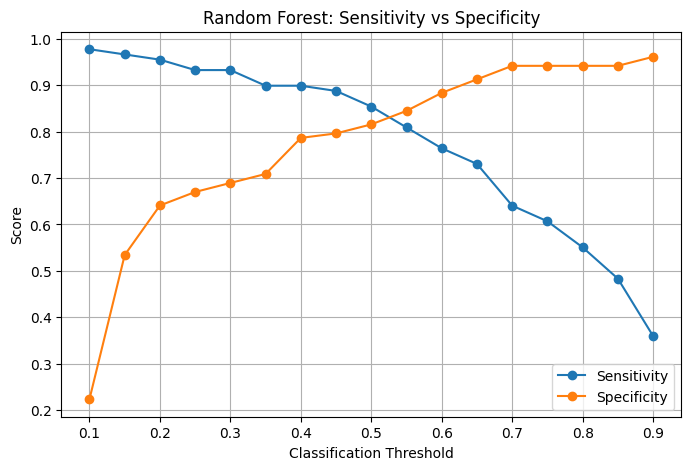

In [23]:
# ============================================================
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    rf_thresholds["Threshold"],
    rf_thresholds["Sensitivity"],
    marker="o",
    label="Sensitivity"
)

plt.plot(
    rf_thresholds["Threshold"],
    rf_thresholds["Specificity"],
    marker="o",
    label="Specificity"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title(
    "Random Forest: Sensitivity vs Specificity"
)

plt.legend()
plt.grid(True)

plt.show()

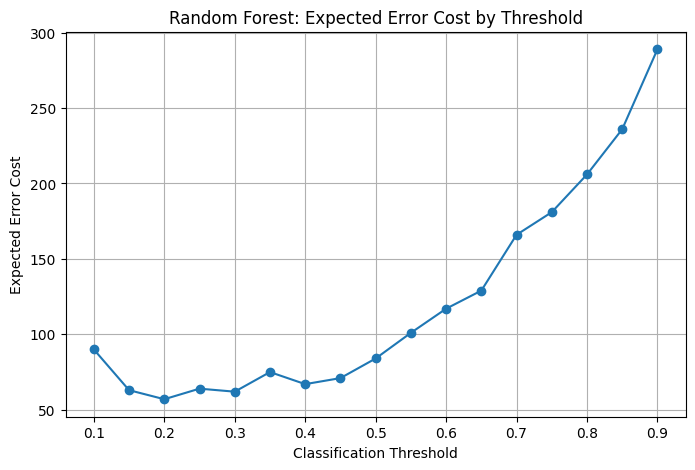

In [24]:
# ============================================================
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    rf_thresholds["Threshold"],
    rf_thresholds["Expected_Cost"],
    marker="o"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Expected Error Cost")
plt.title(
    "Random Forest: Expected Error Cost by Threshold"
)

plt.grid(True)

plt.show()

In [25]:
# ============================================================
# ============================================================

best_rf_row = rf_thresholds.loc[
    rf_thresholds["Expected_Cost"].idxmin()
]

BEST_RF_THRESHOLD = (
    best_rf_row["Threshold"]
)

print(
    f"Selected Random Forest threshold: "
    f"{BEST_RF_THRESHOLD:.2f}"
)

print(
    f"Validation expected cost: "
    f"{best_rf_row['Expected_Cost']:.0f}"
)

Selected Random Forest threshold: 0.20
Validation expected cost: 57


In [26]:
# ============================================================
# ============================================================

best_lr_row = lr_thresholds.loc[
    lr_thresholds["Expected_Cost"].idxmin()
]

BEST_LR_THRESHOLD = (
    best_lr_row["Threshold"]
)

print(
    f"Selected Logistic Regression threshold: "
    f"{BEST_LR_THRESHOLD:.2f}"
)

print(
    f"Validation expected cost: "
    f"{best_lr_row['Expected_Cost']:.0f}"
)

Selected Logistic Regression threshold: 0.15
Validation expected cost: 53


In [27]:
# ============================================================
# ============================================================

lr_cost_result = evaluate_predictions(
    y_val,
    lr_val_prob,
    threshold=BEST_LR_THRESHOLD
)

rf_cost_result = evaluate_predictions(
    y_val,
    rf_val_prob,
    threshold=BEST_RF_THRESHOLD
)

cost_comparison = pd.DataFrame(
    [lr_cost_result, rf_cost_result],
    index=[
        "Logistic Regression",
        "Random Forest"
    ]
)

display(
    cost_comparison[
        [
            "Accuracy",
            "Precision",
            "Sensitivity",
            "Specificity",
            "F1",
            "ROC_AUC",
            "FP",
            "FN"
        ]
    ].round(4)
)

,Accuracy,Precision,Sensitivity,Specificity,F1,ROC_AUC,FP,FN
Logistic Regression,0.7656,0.6692,0.9775,0.5825,0.7945,0.9045,43,2
Random Forest,0.7865,0.6967,0.9551,0.6408,0.8057,0.9023,37,4


In [28]:
# ============================================================
# ============================================================

lr_min_cost = lr_thresholds[
    "Expected_Cost"
].min()

rf_min_cost = rf_thresholds[
    "Expected_Cost"
].min()

print(
    "Minimum Logistic Regression validation cost:",
    lr_min_cost
)

print(
    "Minimum Random Forest validation cost:",
    rf_min_cost
)

if rf_min_cost < lr_min_cost:

    FINAL_MODEL_NAME = "Random Forest"
    FINAL_MODEL = rf_model
    FINAL_THRESHOLD = BEST_RF_THRESHOLD

else:

    FINAL_MODEL_NAME = "Logistic Regression"
    FINAL_MODEL = logistic_model
    FINAL_THRESHOLD = BEST_LR_THRESHOLD

print("\nSelected model:", FINAL_MODEL_NAME)
print("Selected threshold:", FINAL_THRESHOLD)

Minimum Logistic Regression validation cost: 53
Minimum Random Forest validation cost: 57

Selected model: Logistic Regression
Selected threshold: 0.15


## 9. Final held-out test evaluation

Only after selecting the model and threshold from training/validation information is the final test set evaluated. This preserves the role of the test set as an independent final evaluation.

In [29]:
# ============================================================
# ============================================================

final_test_prob = (
    FINAL_MODEL.predict_proba(X_test)[:, 1]
)

print(
    "Final test probabilities generated."
)

Final test probabilities generated.


In [30]:
# ============================================================
# ============================================================

final_test_pred = (
    final_test_prob >= FINAL_THRESHOLD
).astype(int)

print("Final predictions generated.")

Final predictions generated.


In [31]:
# ============================================================
# ============================================================

final_result = evaluate_predictions(
    y_test,
    final_test_prob,
    threshold=FINAL_THRESHOLD
)

final_result_df = pd.DataFrame(
    [final_result],
    index=[FINAL_MODEL_NAME]
)

display(
    final_result_df.round(4)
)

,Accuracy,Precision,Sensitivity,Specificity,F1,ROC_AUC,TN,FP,FN,TP
Logistic Regression,0.7306,0.637,0.9663,0.5288,0.7679,0.9149,55,49,3,86


## 10. Final error analysis and discrimination

The following figures summarize the selected model on the held-out test set. Figures are saved under `results/figures/` so they can later be committed to the GitHub repository.

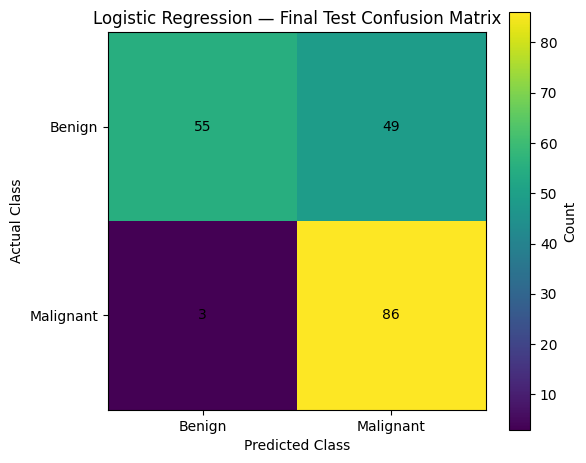

In [32]:
cm = confusion_matrix(y_test, final_test_pred)

plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title(f"{FINAL_MODEL_NAME} — Final Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks([0, 1], ["Benign", "Malignant"])
plt.yticks([0, 1], ["Benign", "Malignant"])

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar(label="Count")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "final_confusion_matrix.png", dpi=200)
plt.show()

In [33]:
# ============================================================
# ============================================================

tn, fp, fn, tp = confusion_matrix(
    y_test,
    final_test_pred
).ravel()

final_cost = (
    C_FN * fn
    + C_FP * fp
)

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives  :", tp)

print("\n--------------------------------")

print("False Positive Cost:",
      C_FP)

print("False Negative Cost:",
      C_FN)

print("\nTotal illustrative error cost:",
      final_cost)

True Negatives : 55
False Positives: 49
False Negatives: 3
True Positives  : 86

--------------------------------
False Positive Cost: 1
False Negative Cost: 5

Total illustrative error cost: 64


In [34]:
# ============================================================
# ============================================================

print(
    classification_report(
        y_test,
        final_test_pred,
        target_names=[
            "Benign",
            "Malignant"
        ],
        digits=4
    )
)

              precision    recall  f1-score   support

      Benign     0.9483    0.5288    0.6790       104
   Malignant     0.6370    0.9663    0.7679        89

    accuracy                         0.7306       193
   macro avg     0.7927    0.7476    0.7234       193
weighted avg     0.8048    0.7306    0.7200       193



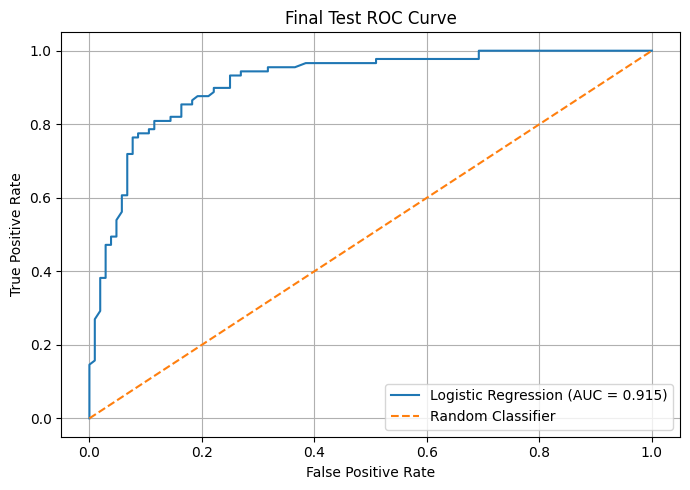

Final ROC-AUC: 0.9149


In [35]:
fpr, tpr, thresholds = roc_curve(y_test, final_test_prob)
auc_score = roc_auc_score(y_test, final_test_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"{FINAL_MODEL_NAME} (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Final Test ROC Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "final_roc_curve.png", dpi=200)
plt.show()
print(f"Final ROC-AUC: {auc_score:.4f}")

In [36]:
# ============================================================
# ============================================================

final_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Sensitivity",
        "Specificity",
        "F1 Score",
        "ROC-AUC"
    ],
    "Value": [
        final_result["Accuracy"],
        final_result["Precision"],
        final_result["Sensitivity"],
        final_result["Specificity"],
        final_result["F1"],
        final_result["ROC_AUC"]
    ]
})

display(
    final_metrics.round(4)
)

,Metric,Value
0,Accuracy,0.7306
1,Precision,0.6370
2,Sensitivity,0.9663
3,Specificity,0.5288
4,F1 Score,0.7679
5,ROC-AUC,0.9149


## 11. Model interpretation

Interpretation here is descriptive rather than causal. Logistic Regression coefficients show learned linear coefficients after preprocessing; Random Forest importance shows impurity-based feature importance.

In [37]:
# ============================================================
# ============================================================

lr_preprocessor = (
    logistic_model
    .named_steps["preprocessing"]
)

lr_estimator = (
    logistic_model
    .named_steps["model"]
)

feature_names = (
    lr_preprocessor
    .get_feature_names_out()
)

coefficients = (
    lr_estimator.coef_[0]
)

coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute_Effect": np.abs(coefficients)
}).sort_values(
    "Absolute_Effect",
    ascending=False
)

display(
    coefficient_table.head(15).round(4)
)

,Feature,Coefficient,Absolute_Effect
4,cat__BI_RADS_5.0,1.6915,1.6915
8,cat__Shape_4.0,0.7979,0.7979
1,cat__BI_RADS_2.0,-0.7346,0.7346
9,cat__Margin_1.0,-0.6802,0.6802
17,cat__Density_4.0,-0.6464,0.6464
0,num__Age,0.6211,0.6211
2,cat__BI_RADS_3.0,-0.5880,0.5880
14,cat__Density_1.0,0.4803,0.4803
6,cat__Shape_2.0,-0.4685,0.4685
10,cat__Margin_2.0,-0.4557,0.4557


In [38]:
# ============================================================
# ============================================================

rf_preprocessor = (
    rf_model
    .named_steps["preprocessing"]
)

rf_estimator = (
    rf_model
    .named_steps["model"]
)

rf_feature_names = (
    rf_preprocessor
    .get_feature_names_out()
)

rf_importance = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_estimator.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

display(
    rf_importance.head(15).round(4)
)

,Feature,Importance
4,cat__BI_RADS_5.0,0.2536
9,cat__Margin_1.0,0.2057
8,cat__Shape_4.0,0.1628
3,cat__BI_RADS_4.0,0.1125
0,num__Age,0.1000
5,cat__Shape_1.0,0.0367
6,cat__Shape_2.0,0.0327
12,cat__Margin_4.0,0.0269
13,cat__Margin_5.0,0.0267
2,cat__BI_RADS_3.0,0.0111


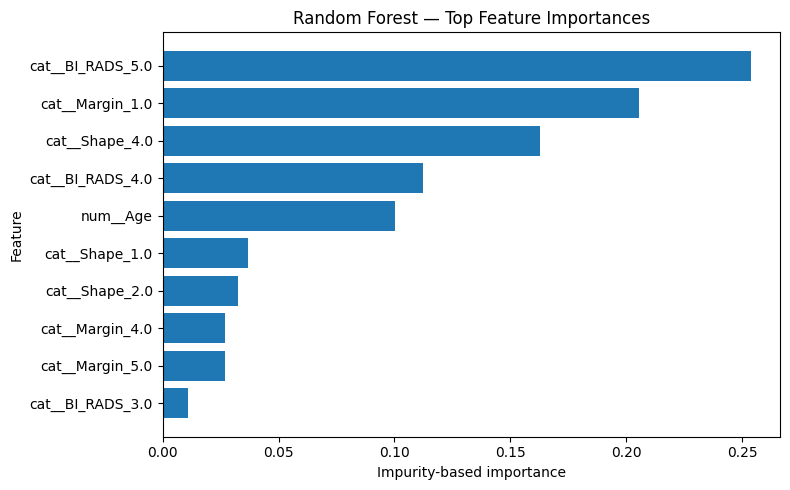

In [39]:
top_features = rf_importance.head(10).sort_values("Importance")

plt.figure(figsize=(8, 5))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Impurity-based importance")
plt.ylabel("Feature")
plt.title("Random Forest — Top Feature Importances")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "random_forest_feature_importance.png", dpi=200)
plt.show()

## 12. BI-RADS sensitivity analysis

BI-RADS is a radiological assessment, so it is important to examine how much predictive performance depends on its availability. The original notebook compared models with and without BI-RADS. This polished version retains that comparison and adds a **BI-RADS-only baseline**.

All three configurations use the same original train/validation rows and a fixed threshold of 0.50 for this sensitivity experiment.

In [40]:
X_no_birads = X.drop(columns=["BI_RADS"])
X_birads_only = X[["BI_RADS"]]

X_train_nb = X_no_birads.loc[X_train.index]
X_val_nb = X_no_birads.loc[X_val.index]

X_train_bo = X_birads_only.loc[X_train.index]
X_val_bo = X_birads_only.loc[X_val.index]

print("Ablation sample sizes:")
print("Train:", len(X_train_nb), "| Validation:", len(X_val_nb))

Ablation sample sizes:
Train: 576 | Validation: 192


In [41]:
def make_preprocessor(numeric_cols, categorical_cols):
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])

    transformers = []
    if numeric_cols:
        transformers.append(("num", numeric_pipe, numeric_cols))
    if categorical_cols:
        transformers.append(("cat", categorical_pipe, categorical_cols))

    return ColumnTransformer(transformers)

def make_rf_model(numeric_cols, categorical_cols):
    return Pipeline([
        ("preprocessing", make_preprocessor(numeric_cols, categorical_cols)),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=5,
            min_samples_leaf=3,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        )),
    ])

rf_no_birads = make_rf_model(
    numeric_cols=["Age"],
    categorical_cols=["Shape", "Margin", "Density"],
)

rf_birads_only = make_rf_model(
    numeric_cols=[],
    categorical_cols=["BI_RADS"],
)

rf_no_birads.fit(X_train_nb, y_train)
rf_birads_only.fit(X_train_bo, y_train)

nb_val_prob = rf_no_birads.predict_proba(X_val_nb)[:, 1]
bo_val_prob = rf_birads_only.predict_proba(X_val_bo)[:, 1]

print("Both ablation models trained.")

Both ablation models trained.


In [42]:
with_birads = evaluate_predictions(y_val, rf_val_prob, threshold=0.50)
without_birads = evaluate_predictions(y_val, nb_val_prob, threshold=0.50)
birads_only = evaluate_predictions(y_val, bo_val_prob, threshold=0.50)

birads_comparison = pd.DataFrame(
    [with_birads, without_birads, birads_only],
    index=["All features", "Without BI-RADS", "BI-RADS only"],
)

display(
    birads_comparison[[
        "Accuracy", "Sensitivity", "Specificity", "F1",
        "ROC_AUC", "FP", "FN"
    ]].round(4)
)

,Accuracy,Sensitivity,Specificity,F1,ROC_AUC,FP,FN
All features,0.8333,0.8539,0.8155,0.8261,0.9023,19,13
Without BI-RADS,0.7760,0.8202,0.7379,0.7725,0.8434,27,16
BI-RADS only,0.8229,0.6966,0.9320,0.7848,0.8180,7,27


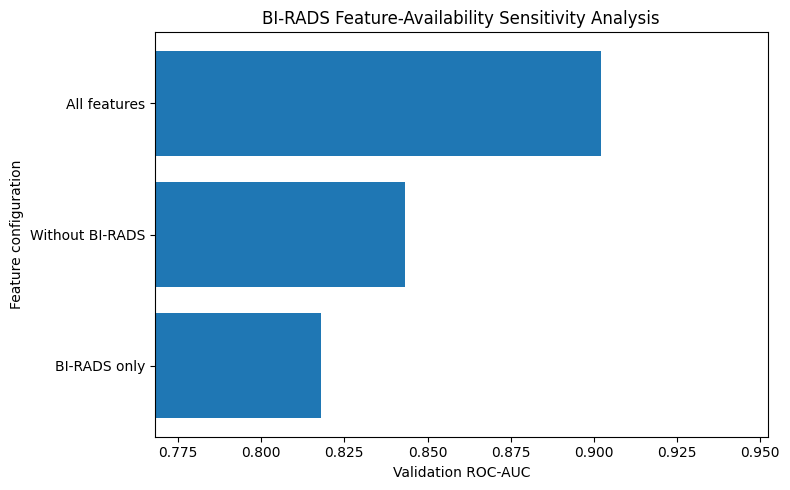

In [43]:
plt.figure(figsize=(8, 5))
auc_values = birads_comparison["ROC_AUC"].sort_values()
plt.barh(auc_values.index, auc_values.values)
plt.xlabel("Validation ROC-AUC")
plt.ylabel("Feature configuration")
plt.title("BI-RADS Feature-Availability Sensitivity Analysis")
plt.xlim(max(0, auc_values.min() - 0.05), min(1, auc_values.max() + 0.05))
plt.tight_layout()
plt.savefig(FIGURE_DIR / "birads_ablation_auc.png", dpi=200)
plt.show()

## 13. Research interpretation and limitations

When interpreting the executed results, focus on:

1. Whether Random Forest materially outperforms Logistic Regression in cross-validation.
2. How the decision threshold changes sensitivity and specificity.
3. Whether the illustrative cost ratio favors fewer false negatives.
4. Whether held-out test performance is consistent with validation performance.
5. How much performance changes when BI-RADS is removed.
6. How much predictive signal is captured by BI-RADS alone.

### Limitations

- The dataset is relatively small for a medical machine-learning study.
- The experiment uses structured tabular variables rather than raw mammographic images.
- No external validation dataset is used.
- The asymmetric error-cost ratio is illustrative, not clinically validated.
- Feature importance does not establish causality.
- BI-RADS availability and timing would require careful consideration before prospective deployment.
- The experiment does not establish clinical utility, safety, or diagnostic performance in practice.

### Conclusion

After execution, report the observed model, selected threshold, held-out test metrics, and BI-RADS sensitivity findings here. Avoid presenting the experiment as a clinical diagnostic system.

In [44]:
summary = {
    "Dataset_samples": len(df),
    "Train_samples": len(X_train),
    "Validation_samples": len(X_val),
    "Test_samples": len(X_test),
    "Selected_model": FINAL_MODEL_NAME,
    "Selected_threshold": FINAL_THRESHOLD,
    "Test_accuracy": final_result["Accuracy"],
    "Test_precision": final_result["Precision"],
    "Test_sensitivity": final_result["Sensitivity"],
    "Test_specificity": final_result["Specificity"],
    "Test_F1": final_result["F1"],
    "Test_ROC_AUC": final_result["ROC_AUC"],
    "Test_false_positives": final_result["FP"],
    "Test_false_negatives": final_result["FN"],
}

summary_df = pd.DataFrame({"Value": summary})
display(summary_df)
print("\nFigures saved to:", FIGURE_DIR)

,Value
Dataset_samples,961
Train_samples,576
Validation_samples,192
Test_samples,193
Selected_model,Logistic Regression
Selected_threshold,0.15
Test_accuracy,0.73057
Test_precision,0.637037
Test_sensitivity,0.966292
Test_specificity,0.528846



Figures saved to: /kaggle/working/results/figures


In [45]:
# ============================================================
# SAVE RESEARCH RESULTS FOR GITHUB
# ============================================================

from pathlib import Path

RESULTS_DIR = Path("/kaggle/working/results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# 1. Model comparison
model_comparison.to_csv(
    RESULTS_DIR / "model_comparison.csv"
)

# 2. Final independent test results
final_result_df.to_csv(
    RESULTS_DIR / "final_test_results.csv"
)

# 3. BI-RADS sensitivity analysis
birads_comparison.to_csv(
    RESULTS_DIR / "birads_sensitivity.csv"
)

print("CSV files created successfully:")
print("1.", RESULTS_DIR / "model_comparison.csv")
print("2.", RESULTS_DIR / "final_test_results.csv")
print("3.", RESULTS_DIR / "birads_sensitivity.csv")

CSV files created successfully:
1. /kaggle/working/results/model_comparison.csv
2. /kaggle/working/results/final_test_results.csv
3. /kaggle/working/results/birads_sensitivity.csv
